# Model Training: Vehicle Insurance Cross-Sell Response

This notebook follows the same steps as the tutorial's model-training notebook, rewritten for a **binary classification** problem:

1. Import packages and data
2. Feature engineering (decisions from the EDA, section 5.2)
3. Chronological train / validation / test split
4. Prepare X and y, and build the preprocessors
5. Evaluation function (PR-AUC, ROC-AUC, recall, precision, F1, top-10% lift, Brier)
6. Baseline, then train every model and compare the results
7. Hyperparameter tuning with time-ordered cross-validation
8. Agent-as-proxy check
9. Calibration and decision threshold (validation data only)
10. Final evaluation on the sealed test window, fairness check and feature importance
11. Score the unlabelled file and save the model

**Rule:** the test window is used **once**, at step 10, after every choice is fixed.

#### 1.1 Import Data and Required Packages

In [3]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

warnings.filterwarnings("ignore")  # remove later to check for convergence warnings

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (OneHotEncoder, StandardScaler, KBinsDiscretizer,
                                   FunctionTransformer, TargetEncoder)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, log_loss,
                             precision_recall_curve, roc_curve,
                             recall_score, precision_score, f1_score, confusion_matrix)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator  # needs scikit-learn 1.6 or newer
from sklearn.inspection import permutation_importance

try:
    from lightgbm import LGBMClassifier
except ImportError:
    raise ImportError("LightGBM is not installed. In your venv terminal run: python -m pip install lightgbm")

import sklearn
print("scikit-learn version:", sklearn.__version__)
RANDOM_STATE = 42

scikit-learn version: 1.9.1


#### Import the CSV Data as Pandas DataFrame

In [4]:
train_raw = pd.read_csv("data/train_data_cross-sell.csv", dtype={"id": str}, encoding="utf-8-sig")
score_raw = pd.read_csv("data/test_data_cross-sell.csv", dtype={"id": str}, encoding="utf-8-sig")
print("Labelled:", train_raw.shape, "| Unlabelled (final scoring):", score_raw.shape)

Labelled: (324466, 12) | Unlabelled (final scoring): (56643, 11)


#### Show Top 5 Records

In [5]:
train_raw.head()

,id,Gender,Customer_Date_of_Birth,Driving_License,Customer_Residence_Sub_County,Previously_Insured,Vehicle_Year_of_Manufacture,Vehicle_Damage,Annual_Premium,Agent_name,Life_policy_start_date,Response
0,549771831,Male,"Monday, March 7, 1977",1,EMBAKASI,0,2020,Yes,38294,Jomo Kenyatta,"Thursday, December 21, 2023",1
1,373583351,Male,"Sunday, December 29, 2002",1,WESTLANDS,1,2020,No,28619,Obiero Ochieng,"Wednesday, June 28, 2023",0
2,933163655,Female,"Tuesday, August 23, 1994",1,DAGORETTI,1,2011,No,27496,Obiero Ochieng,"Saturday, December 9, 2023",0
3,698942186,Female,"Thursday, November 18, 1999",1,JUJA,0,2020,Yes,2630,Gitonga Mwangi,"Tuesday, July 25, 2023",0
4,515109822,Male,"Thursday, February 22, 2001",1,WESTLANDS,0,2015,Yes,23367,Obiero Ochieng,"Saturday, May 13, 2023",0


## 2) Feature engineering

One function turns the raw columns into model features, so the same code runs on the training data, the unlabelled file and later on a single API request. Everything is measured **at the policy start date** (EDA 5.2: no information from after the policy began).

| Feature | Why (EDA) |
|---|---|
| `age`, `vehicle_age` | derived from the text dates (3.7) |
| `damage_not_insured` | the segment holding about 97% of responders (4.4.2) |
| `premium_floor_flag` | the spike at the minimum premium of 2,630 (4.4.3) |
| `id` dropped | repeated ids, not a customer key (3.2) |

In [6]:
DATE_FORMAT = "%A, %B %d, %Y"
PREMIUM_FLOOR = 2630

def engineer_features(df):
    policy_date = pd.to_datetime(df["Life_policy_start_date"], format=DATE_FORMAT)
    birth_date = pd.to_datetime(df["Customer_Date_of_Birth"], format=DATE_FORMAT)
    out = pd.DataFrame(index=df.index)
    out["age"] = (policy_date - birth_date).dt.days / 365.25
    out["vehicle_age"] = policy_date.dt.year - df["Vehicle_Year_of_Manufacture"]
    out["Annual_Premium"] = df["Annual_Premium"].astype(float)
    out["premium_floor_flag"] = (df["Annual_Premium"] == PREMIUM_FLOOR).astype(int)
    out["Gender"] = df["Gender"]
    out["Vehicle_Damage"] = df["Vehicle_Damage"]
    out["Driving_License"] = df["Driving_License"]
    out["Previously_Insured"] = df["Previously_Insured"]
    out["damage_not_insured"] = ((df["Vehicle_Damage"] == "Yes") & (df["Previously_Insured"] == 0)).astype(int)
    out["Customer_Residence_Sub_County"] = df["Customer_Residence_Sub_County"].astype(str)
    out["Agent_name"] = df["Agent_name"].astype(str)
    return out

engineer_features(train_raw.head())

,age,vehicle_age,Annual_Premium,premium_floor_flag,Gender,Vehicle_Damage,Driving_License,Previously_Insured,damage_not_insured,Customer_Residence_Sub_County,Agent_name
0,46.789870,3,38294.0,0,Male,Yes,1,0,1,EMBAKASI,Jomo Kenyatta
1,20.495551,3,28619.0,0,Male,No,1,1,0,WESTLANDS,Obiero Ochieng
2,29.295003,12,27496.0,0,Female,No,1,1,0,DAGORETTI,Obiero Ochieng
3,23.682409,3,2630.0,1,Female,Yes,1,0,1,JUJA,Gitonga Mwangi
4,22.217659,8,23367.0,0,Male,Yes,1,0,1,WESTLANDS,Obiero Ochieng


## 3) Chronological split (70 / 15 / 15)

The tutorial uses `train_test_split` (random). Here the split is by `Life_policy_start_date`, so the model is always tested on **later** policies than it was trained on, which is how it would be used in practice (EDA 4.5.1).

In [7]:
policy_date = pd.to_datetime(train_raw["Life_policy_start_date"], format=DATE_FORMAT)
df = train_raw.assign(_date=policy_date).sort_values("_date", kind="mergesort").reset_index(drop=True)

cut_1, cut_2 = df["_date"].quantile(0.70), df["_date"].quantile(0.85)
train_df = df[df["_date"] <= cut_1]
val_df = df[(df["_date"] > cut_1) & (df["_date"] <= cut_2)]
test_df = df[df["_date"] > cut_2]

pd.DataFrame({
    "rows": [len(train_df), len(val_df), len(test_df)],
    "response_rate": [train_df["Response"].mean(), val_df["Response"].mean(), test_df["Response"].mean()],
    "first_date": [train_df["_date"].min().date(), val_df["_date"].min().date(), test_df["_date"].min().date()],
    "last_date": [train_df["_date"].max().date(), val_df["_date"].max().date(), test_df["_date"].max().date()],
}, index=["train", "validation", "test"]).round(4)

,rows,response_rate,first_date,last_date
train,227964,0.1227,2023-03-24,2023-10-13
validation,48394,0.1210,2023-10-14,2023-11-25
test,48108,0.1250,2023-11-26,2024-01-07


#### Preparing X and y variables

In [8]:
target = "Response"
X_train, y_train = engineer_features(train_df), train_df[target].values
X_val, y_val = engineer_features(val_df), val_df[target].values
X_test, y_test = engineer_features(test_df), test_df[target].values
X_score = engineer_features(score_raw)

print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape, "| X_score:", X_score.shape)
X_train.head()

X_train: (227964, 11) | X_val: (48394, 11) | X_test: (48108, 11) | X_score: (56643, 11)


,age,vehicle_age,Annual_Premium,premium_floor_flag,Gender,Vehicle_Damage,Driving_License,Previously_Insured,damage_not_insured,Customer_Residence_Sub_County,Agent_name
0,24.098563,5,46622.0,0,Female,No,1,1,0,BUNGOMA SOUTH,Obiero Ochieng
1,24.016427,11,2630.0,1,Female,No,1,1,0,KISAUNI,Gitonga Mwangi
2,40.298426,2,30438.0,0,Female,Yes,1,0,1,BUMULA,Njoroge Karanja
3,35.712526,5,34545.0,0,Male,No,1,1,0,SOTIK,Njoroge Karanja
4,54.209446,7,28289.0,0,Male,Yes,1,0,1,IGEMBE CENTRAL,Njoroge Karanja


## 4) Preprocessors

The tutorial uses one `ColumnTransformer` (OneHotEncoder + StandardScaler). Here each model family gets its own, following EDA 5.2:

| Step | Logistic Regression (`linear`) | Tree models (`tree`) |
|---|---|---|
| Age | quantile bands (`KBinsDiscretizer`), for the hump shape | raw |
| Premium | log + cap at the 99th percentile, then scaled | raw |
| Gender, Vehicle_Damage | one-hot | one-hot |
| Sub-county, agent | `TargetEncoder` (cross-fitted inside folds, smoothed, unseen → global rate), then scaled | `TargetEncoder` |
| Damage × not-insured | included as an interaction | not needed (trees find it) |

In [9]:
num_raw = ["age", "vehicle_age", "Annual_Premium"]
binary = ["Driving_License", "Previously_Insured", "premium_floor_flag"]
cat_low = ["Gender", "Vehicle_Damage"]
PREMIUM_CAP = X_train["Annual_Premium"].quantile(0.99)

def log_cap(x):
    return np.log1p(np.clip(x, None, PREMIUM_CAP))

def make_target_encoder():
    return TargetEncoder(target_type="binary", smooth="auto", cv=5, shuffle=True, random_state=RANDOM_STATE)

def get_preprocessor(kind, use_agent=True):
    high_card = ["Customer_Residence_Sub_County", "Agent_name"] if use_agent else ["Customer_Residence_Sub_County"]
    if kind == "linear":
        transformers = [
            ("age_bands", KBinsDiscretizer(n_bins=6, encode="onehot", strategy="quantile"), ["age"]),
            ("premium", Pipeline([("log_cap", FunctionTransformer(log_cap, feature_names_out="one-to-one")), ("scale", StandardScaler())]), ["Annual_Premium"]),
            ("vehicle_age", StandardScaler(), ["vehicle_age"]),
            ("onehot", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_low),
            ("binary", "passthrough", binary + ["damage_not_insured"]),
            ("target_enc", Pipeline([("enc", make_target_encoder()), ("scale", StandardScaler())]), high_card),
        ]
    else:
        transformers = [
            ("numeric", "passthrough", num_raw),
            ("onehot", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_low),
            ("binary", "passthrough", binary),
            ("target_enc", make_target_encoder(), high_card),
        ]
    return ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=False)

get_preprocessor("linear").fit(X_train, y_train).get_feature_names_out()

array(['age_0.0', 'age_1.0', 'age_2.0', 'age_3.0', 'age_4.0', 'age_5.0',
       'Annual_Premium', 'vehicle_age', 'Gender_Male',
       'Vehicle_Damage_Yes', 'Driving_License', 'Previously_Insured',
       'premium_floor_flag', 'damage_not_insured',
       'Customer_Residence_Sub_County', 'Agent_name'], dtype=object)

#### Create an Evaluate Function to give all metrics after model training

The tutorial reports MAE, RMSE and R². For an imbalanced classification problem (12.3% positive), accuracy would be misleading, so the metrics are the ones from the proposal. **PR-AUC is the main metric.** Its random baseline equals the response rate (about 0.12).

In [10]:
def lift_at_k(y_true, y_prob, k=0.10):
    """Response rate in the top k share of customers divided by the overall response rate."""
    n_top = int(round(len(y_true) * k))
    top = np.argsort(-y_prob)[:n_top]
    return y_true[top].mean() / y_true.mean()

def evaluate_model(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "PR-AUC": average_precision_score(y_true, y_prob),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Top-10% lift": lift_at_k(y_true, y_prob),
        "Brier": brier_score_loss(y_true, y_prob),
    }

## 5) Train the models and compare them on validation

Same idea as the tutorial's loop over a `models` dictionary. Each model is a `Pipeline(preprocessor → model)`, so the target encoder only ever learns from the data it is fitted on. **Class weights** handle the 7 : 1 imbalance. The Dummy classifier is the baseline every model must beat.

In [11]:
models = {
    "Baseline (Dummy)": ("tree", DummyClassifier(strategy="prior")),
    "Logistic Regression": ("linear", LogisticRegression(class_weight="balanced", C=1.0, max_iter=2000)),
    "Random Forest": ("tree", RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=200,
                                                     class_weight="balanced_subsample", n_jobs=-1,
                                                     random_state=RANDOM_STATE)),
    "LightGBM": ("tree", LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                                        class_weight="balanced", random_state=RANDOM_STATE, verbose=-1)),
}

fitted, results = {}, []
for name, (kind, model) in models.items():
    start = time.time()
    pipe = Pipeline([("preprocessor", get_preprocessor(kind)), ("model", model)])
    pipe.fit(X_train, y_train)
    train_prob = pipe.predict_proba(X_train)[:, 1]
    val_prob = pipe.predict_proba(X_val)[:, 1]
    fitted[name] = pipe

    row = {"Model": name, "Train PR-AUC": average_precision_score(y_train, train_prob)}
    row.update(evaluate_model(y_val, val_prob))
    row["Seconds"] = round(time.time() - start, 1)
    results.append(row)
    print(f"{name}: validation PR-AUC {row['PR-AUC']:.4f} ({row['Seconds']}s)")

Baseline (Dummy): validation PR-AUC 0.1210 (2.0s)
Logistic Regression: validation PR-AUC 0.3377 (3.9s)
Random Forest: validation PR-AUC 0.3512 (27.1s)
LightGBM: validation PR-AUC 0.3533 (9.1s)


### Results (validation window)

In [12]:
results_df = pd.DataFrame(results).set_index("Model").sort_values("PR-AUC", ascending=False)
results_df.round(4)

,Train PR-AUC,PR-AUC,ROC-AUC,Recall,Precision,F1,Top-10% lift,Brier,Seconds
Model,,,,,,,,,
LightGBM,0.3820,0.3533,0.8537,0.9224,0.2788,0.4282,3.1793,0.1720,9.1
Random Forest,0.3748,0.3512,0.8527,0.9320,0.2744,0.4240,3.1810,0.1730,27.1
Logistic Regression,0.3475,0.3377,0.8477,0.9354,0.2721,0.4216,3.0153,0.1780,3.9
Baseline (Dummy),0.1227,0.1210,0.5000,0.0000,0.0000,0.0000,0.9755,0.1063,2.0


**How to read this:**
- Recall, precision and F1 here use the default 0.5 threshold. With class weights that flags far more customers than a budget allows, so they are compared properly only after the threshold is chosen (section 8).
- Brier is high for the weighted models because class weights push probabilities up. Calibration (section 8) fixes this.
- A large gap between **Train PR-AUC** and validation PR-AUC means overfitting.

*Write your own observations here once it has run.*

## 6) Hyperparameter tuning (time-ordered cross-validation)

`RandomizedSearchCV` with `TimeSeriesSplit`: every fold trains on earlier policies and validates on later ones inside the training window, scored by PR-AUC. Logistic Regression and LightGBM are tuned. Random Forest is kept at sensible settings because each fit takes much longer.

In [13]:
search_spaces = {
    "Logistic Regression": ("linear", LogisticRegression(class_weight="balanced", max_iter=2000),
                            {"model__C": [0.01, 0.1, 1.0, 10.0]}),
    "LightGBM": ("tree", LGBMClassifier(class_weight="balanced", random_state=RANDOM_STATE, verbose=-1),
                 {"model__num_leaves": [15, 31, 63],
                  "model__learning_rate": [0.03, 0.05, 0.1],
                  "model__n_estimators": [200, 400],
                  "model__min_child_samples": [50, 200]}),
}

tuned_rows = []
for name, (kind, model, params) in search_spaces.items():
    start = time.time()
    search = RandomizedSearchCV(
        Pipeline([("preprocessor", get_preprocessor(kind)), ("model", model)]),
        params, n_iter=6, scoring="average_precision", cv=TimeSeriesSplit(n_splits=3),
        random_state=RANDOM_STATE, n_jobs=1)
    search.fit(X_train, y_train)
    val_pr_auc = average_precision_score(y_val, search.best_estimator_.predict_proba(X_val)[:, 1])
    fitted[name + " (tuned)"] = search.best_estimator_
    tuned_rows.append({"Model": name + " (tuned)", "CV PR-AUC": search.best_score_,
                       "Validation PR-AUC": val_pr_auc, "Best params": search.best_params_,
                       "Seconds": round(time.time() - start, 1)})
    print(f"{name}: best CV PR-AUC {search.best_score_:.4f}, validation {val_pr_auc:.4f}, {search.best_params_}")

pd.DataFrame(tuned_rows).set_index("Model")

Logistic Regression: best CV PR-AUC 0.3438, validation 0.3374, {'model__C': 1.0}
LightGBM: best CV PR-AUC 0.3600, validation 0.3550, {'model__num_leaves': 31, 'model__n_estimators': 200, 'model__min_child_samples': 50, 'model__learning_rate': 0.05}


,CV PR-AUC,Validation PR-AUC,Best params,Seconds
Model,,,,
Logistic Regression (tuned),0.343833,0.337446,{'model__C': 1.0},25.4
LightGBM (tuned),0.360003,0.355037,"{'model__num_leaves': 31, 'model__n_estimators...",61.4


#### Choose the best model (highest validation PR-AUC)

In [14]:
val_scores = {name: average_precision_score(y_val, m.predict_proba(X_val)[:, 1])
              for name, m in fitted.items() if not name.startswith("Baseline")}
best_name = max(val_scores, key=val_scores.get)
best_model = fitted[best_name]

pd.Series(val_scores, name="Validation PR-AUC").sort_values(ascending=False).round(4).to_frame()

,Validation PR-AUC
LightGBM (tuned),0.3550
LightGBM,0.3533
Random Forest,0.3512
Logistic Regression,0.3377
Logistic Regression (tuned),0.3374


In [15]:
print("Best model:", best_name)

Best model: LightGBM (tuned)


## 7) Agent-as-proxy check

EDA 4.4.4 found large differences between agents. If the model leans on `Agent_name`, it may be learning *who sold the policy* rather than *who the customer is*. The same model is refitted without the agent column, and the drop in PR-AUC shows how much it depends on agent.

In [16]:
kind = "linear" if best_name.startswith("Logistic") else "tree"
no_agent = Pipeline([("preprocessor", get_preprocessor(kind, use_agent=False)),
                     ("model", sklearn.base.clone(best_model.named_steps["model"]))])
no_agent.fit(X_train, y_train)
with_agent_auc = val_scores[best_name]
without_agent_auc = average_precision_score(y_val, no_agent.predict_proba(X_val)[:, 1])
print(f"Validation PR-AUC with agent:    {with_agent_auc:.4f}")
print(f"Validation PR-AUC without agent: {without_agent_auc:.4f}")
print(f"Difference:                      {with_agent_auc - without_agent_auc:+.4f}")

Validation PR-AUC with agent:    0.3550
Validation PR-AUC without agent: 0.3407
Difference:                      +0.0144


*Interpret: a small drop means agent adds a little signal; a large drop means the model depends on agent and the proxy risk needs discussing.*

## 8) Calibration and decision threshold (validation only)

Class weights inflate probabilities, so the best model is calibrated on the validation window with **sigmoid (Platt) scaling**. Sigmoid is used rather than isotonic because isotonic creates tied probabilities at the top of the list, and the customer ranking is the whole point of prioritisation.

Brier before calibration: 0.1734
Brier after calibration:  0.0865


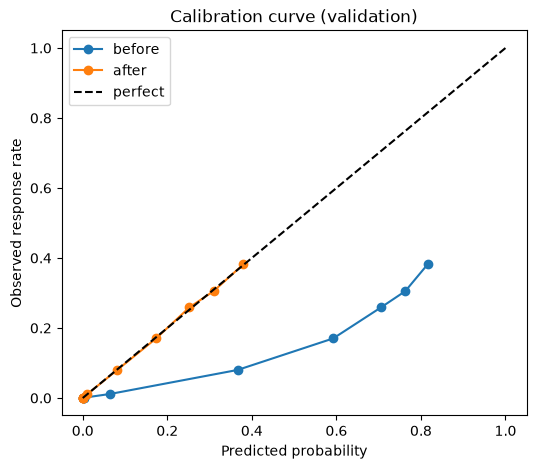

In [17]:
calibrated = CalibratedClassifierCV(FrozenEstimator(best_model), method="sigmoid")
calibrated.fit(X_val, y_val)

val_prob_raw = best_model.predict_proba(X_val)[:, 1]
val_prob_cal = calibrated.predict_proba(X_val)[:, 1]
print(f"Brier before calibration: {brier_score_loss(y_val, val_prob_raw):.4f}")
print(f"Brier after calibration:  {brier_score_loss(y_val, val_prob_cal):.4f}")

fig, ax = plt.subplots(figsize=(6, 5))
for label, p in [("before", val_prob_raw), ("after", val_prob_cal)]:
    frac_pos, mean_pred = calibration_curve(y_val, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=label)
ax.plot([0, 1], [0, 1], "k--", label="perfect")
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed response rate")
ax.set_title("Calibration curve (validation)"); ax.legend()
plt.show()

#### Choosing the threshold

The threshold is the probability above which a customer is contacted. It is chosen on validation by maximising F1 (a balance of recall and precision). The table shows the trade-off at other thresholds, so the business can pick one that fits its outreach budget.

In [18]:
thresholds = np.round(np.arange(0.05, 0.61, 0.01), 2)
f1s = [f1_score(y_val, (val_prob_cal >= t).astype(int)) for t in thresholds]
threshold = float(thresholds[int(np.argmax(f1s))])
print("Chosen threshold (max F1 on validation):", threshold)

trade_off = pd.DataFrame([{
    "threshold": t,
    "share_contacted": (val_prob_cal >= t).mean(),
    "recall": recall_score(y_val, (val_prob_cal >= t).astype(int)),
    "precision": precision_score(y_val, (val_prob_cal >= t).astype(int), zero_division=0),
} for t in [0.10, 0.15, 0.20, threshold, 0.30, 0.40]]).drop_duplicates("threshold").sort_values("threshold")
trade_off.round(3)

Chosen threshold (max F1 on validation): 0.23


,threshold,share_contacted,recall,precision
0,0.10,0.431,0.950,0.267
1,0.15,0.375,0.896,0.289
2,0.20,0.320,0.816,0.309
3,0.23,0.285,0.755,0.321
4,0.30,0.172,0.504,0.356
5,0.40,0.023,0.081,0.426


## 9) Final evaluation on the sealed test window

Scored **once**. Nothing below is used to change the model.

In [19]:
test_prob = calibrated.predict_proba(X_test)[:, 1]
test_metrics = evaluate_model(y_test, test_prob, threshold)
baseline_metrics = evaluate_model(y_test, np.full(len(y_test), y_train.mean()), threshold)
pd.DataFrame({best_name + " (calibrated)": test_metrics, "Baseline": baseline_metrics}).round(4)

,LightGBM (tuned) (calibrated),Baseline
PR-AUC,0.3654,0.1250
ROC-AUC,0.8544,0.5000
Recall,0.7487,0.0000
Precision,0.3298,0.0000
F1,0.4579,0.0000
Top-10% lift,3.1048,0.9961
Brier,0.0883,0.1094


#### Plots: PR curve, ROC curve and confusion matrix (the classification version of the tutorial's actual-vs-predicted plot)

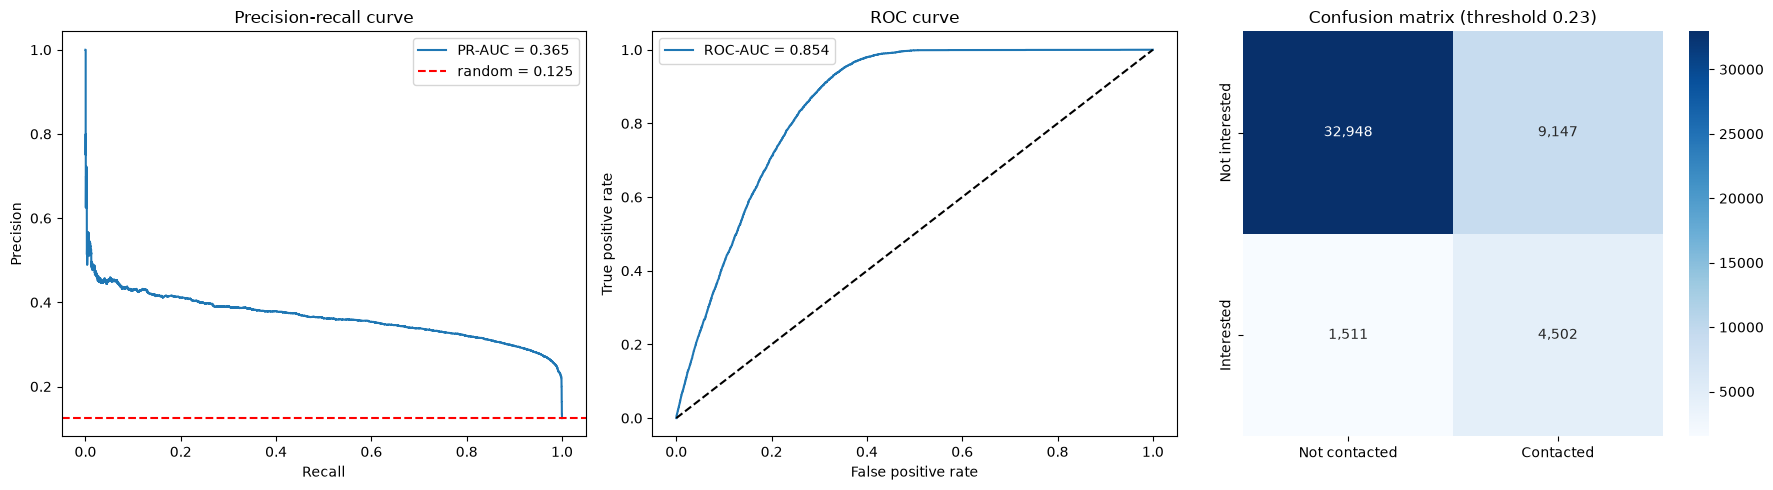

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

prec, rec, _ = precision_recall_curve(y_test, test_prob)
axes[0].plot(rec, prec, label=f"PR-AUC = {test_metrics['PR-AUC']:.3f}")
axes[0].axhline(y_test.mean(), color="red", linestyle="--", label=f"random = {y_test.mean():.3f}")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_title("Precision-recall curve"); axes[0].legend()

fpr, tpr, _ = roc_curve(y_test, test_prob)
axes[1].plot(fpr, tpr, label=f"ROC-AUC = {test_metrics['ROC-AUC']:.3f}")
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].set_title("ROC curve"); axes[1].legend()

cm = confusion_matrix(y_test, (test_prob >= threshold).astype(int))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", ax=axes[2],
            xticklabels=["Not contacted", "Contacted"], yticklabels=["Not interested", "Interested"])
axes[2].set_title(f"Confusion matrix (threshold {threshold})")
plt.tight_layout(); plt.show()

#### Lift by decile: what the model means for the outreach budget

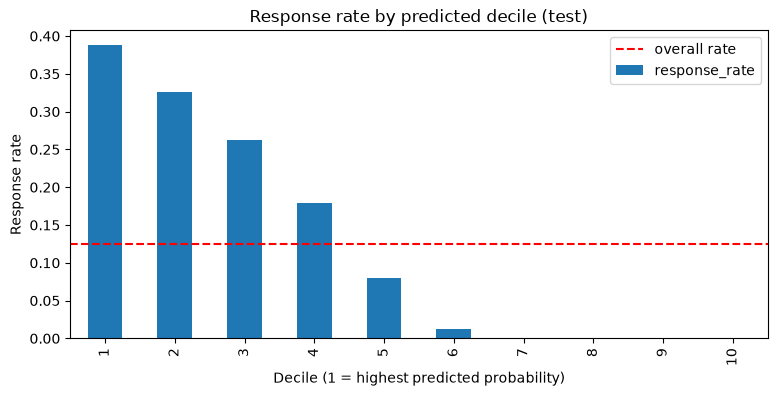

,customers,responders,response_rate,lift,cumulative_share_of_responders
decile,,,,,
1,4811,1867,0.388,3.105,0.310
2,4811,1568,0.326,2.608,0.571
3,4811,1262,0.262,2.099,0.781
4,4810,862,0.179,1.434,0.924
5,4811,387,0.080,0.644,0.989
6,4811,61,0.013,0.101,0.999
7,4810,2,0.000,0.003,0.999
8,4811,1,0.000,0.002,1.000
9,4811,1,0.000,0.002,1.000


In [21]:
deciles = pd.DataFrame({"y": y_test, "p": test_prob})
deciles["decile"] = pd.qcut(deciles["p"].rank(ascending=False, method="first"), 10, labels=range(1, 11))
lift_table = deciles.groupby("decile", observed=True).agg(customers=("y", "size"), responders=("y", "sum"),
                                                          response_rate=("y", "mean"))
lift_table["lift"] = lift_table["response_rate"] / y_test.mean()
lift_table["cumulative_share_of_responders"] = lift_table["responders"].cumsum() / lift_table["responders"].sum()

ax = lift_table["response_rate"].plot(kind="bar", figsize=(9, 4))
ax.axhline(y_test.mean(), color="red", linestyle="--", label="overall rate")
ax.set_xlabel("Decile (1 = highest predicted probability)"); ax.set_ylabel("Response rate")
ax.set_title("Response rate by predicted decile (test)"); ax.legend()
plt.show()
lift_table.round(3)

#### Fairness check by gender (EDA 4.4.1: base rates 13.8% male vs 10.5% female)

In [22]:
fair = pd.DataFrame({"y": y_test, "p": test_prob, "gender": test_df["Gender"].values})
fair["contacted"] = (fair["p"] >= threshold).astype(int)
fairness = fair.groupby("gender").apply(lambda g: pd.Series({
    "customers": len(g),
    "base_rate": g["y"].mean(),
    "share_contacted": g["contacted"].mean(),
    "recall": recall_score(g["y"], g["contacted"]),
    "precision": precision_score(g["y"], g["contacted"], zero_division=0),
    "PR-AUC": average_precision_score(g["y"], g["p"]),
}))
print("Contact-rate ratio (lower / higher):",
      round(fairness["share_contacted"].min() / fairness["share_contacted"].max(), 3))
print("Recall gap:", round(fairness["recall"].max() - fairness["recall"].min(), 3))
fairness.round(3)

Contact-rate ratio (lower / higher): 0.69
Recall gap: 0.037


,customers,base_rate,share_contacted,recall,precision,PR-AUC
gender,,,,,,
Female,22059.0,0.108,0.228,0.727,0.344,0.376
Male,26049.0,0.139,0.331,0.763,0.322,0.358


*Interpret: a lower contact rate for women can simply follow their lower base rate. A similar recall for both groups means interested customers of either gender are found equally well.*

#### Feature importance (permutation importance on a validation sample)

How much PR-AUC drops when each raw feature is shuffled. This works for any model. SHAP values (from the proposal) can be added in the next step with `pip install shap`.

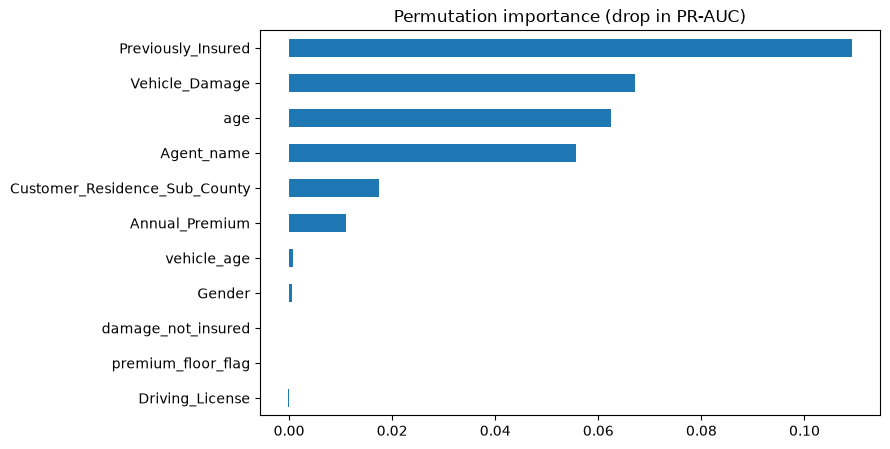

,importance
Previously_Insured,0.1092
Vehicle_Damage,0.0671
age,0.0625
Agent_name,0.0556
Customer_Residence_Sub_County,0.0174
Annual_Premium,0.0110
vehicle_age,0.0008
Gender,0.0006
premium_floor_flag,0.0000
damage_not_insured,0.0000


In [23]:
sample = X_val.sample(10000, random_state=RANDOM_STATE)
imp = permutation_importance(best_model, sample, y_val[X_val.index.get_indexer(sample.index)],
                             scoring="average_precision", n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
importance = pd.Series(imp.importances_mean, index=sample.columns).sort_values()
importance.plot(kind="barh", figsize=(8, 5), title="Permutation importance (drop in PR-AUC)")
plt.show()
importance.sort_values(ascending=False).round(4).to_frame("importance")

## 10) Score the unlabelled file and save the model

The unlabelled customers are ranked for outreach: `priority_rank` 1 is called first.

In [24]:
score_prob = calibrated.predict_proba(X_score)[:, 1]
priority = pd.DataFrame({"id": score_raw["id"], "probability": score_prob,
                         "contact": (score_prob >= threshold).astype(int)})
priority["priority_rank"] = priority["probability"].rank(ascending=False, method="first").astype(int)
priority = priority.sort_values("priority_rank")
print(f"Customers recommended for contact: {priority['contact'].sum():,} of {len(priority):,} "
      f"({priority['contact'].mean():.1%})")
priority.head(10)

Customers recommended for contact: 15,954 of 56,643 (28.2%)


,id,probability,contact,priority_rank
54434,58284032,0.509979,1,1
1326,16548999,0.506551,1,2
54117,68372431,0.503272,1,3
42809,62983518,0.499841,1,4
47661,135923114,0.498777,1,5
14680,118307831,0.493842,1,6
41611,46106663,0.493596,1,7
53566,147930927,0.488963,1,8
16874,10826007,0.488428,1,9
25110,119945747,0.485102,1,10


In [25]:
os.makedirs("models", exist_ok=True)
joblib.dump({"model": calibrated, "threshold": threshold, "model_name": best_name}, "models/model_notebook.pkl")
priority.to_csv("models/priority_list.csv", index=False)
print("Saved models/model_notebook.pkl and models/priority_list.csv")

Saved models/model_notebook.pkl and models/priority_list.csv


## Conclusions

*Fill in after running:*
- Best model and its test PR-AUC, ROC-AUC and top-10% lift compared with the baseline
- Whether agent matters (section 7)
- Chosen threshold, share of customers contacted, and recall at that threshold
- Fairness result
- Most important features, and whether `Driving_License` and `vehicle_age` can be dropped (EDA 5.2)

The next step moves this notebook's code into `src/Components/` (data_ingestion, data_transformation, model_trainer), as the tutorial does.